Universidade do Vale do Itajaí

Curso: Ciência da Computação

Disciplina: Processamento de Imagens

Professor: Felipe Viel

Projeto M2.1 – Processamento Morfológico

Acadêmicos: Aquilis Visintainer, Filipe Dietrich e Nilton Alves

In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage.util import random_noise

# 1. Erosão Morfológica

## Justificativa da implementação

A erosão morfológica é uma operação que utilizamos para reduzir as regiões de primeiro plano em imagens binárias, permitindo assim, remover pequenos detalhes, diminuir a espessura de estruturas e eliminar conexões estreitas entre componentes da imagem.
Para seu funcionamento é necessário um elemento estruturante, que determina o tamanho e a forma da vizinhança analisada. Na erosão binária, um pixel permanece branco somente quando todos os pixels correspondentes às posições ativas do elemento estruturante também pertencem ao primeiro plano.
Para este experimento, a erosão será implementada manualmente, percorrendo os pixels da imagem e verificando suas respectivas vizinhanças.

Serão utilizados três elementos estruturantes:

- **Quadrado 3×3:** para observar a redução das estruturas utilizando uma vizinhança pequena.
- **Cruz 3×3:** para avaliar a influência da forma do elemento estruturante sobre a erosão.
- **Quadrado 5×5:** para verificar o efeito do aumento da área de atuação sobre a preservação dos detalhes.

O objetivo desta etapa é avaliar como o tamanho e a forma do elemento estruturante influenciam a redução das regiões, a preservação dos contornos e a possível perda de informações.

Iniciando erosão com elemento quadrado 3x3...
Iniciando erosão com elemento cruz 3x3...
Iniciando erosão com elemento quadrado 5x5...
Erosão concluída! Gerando visualização...


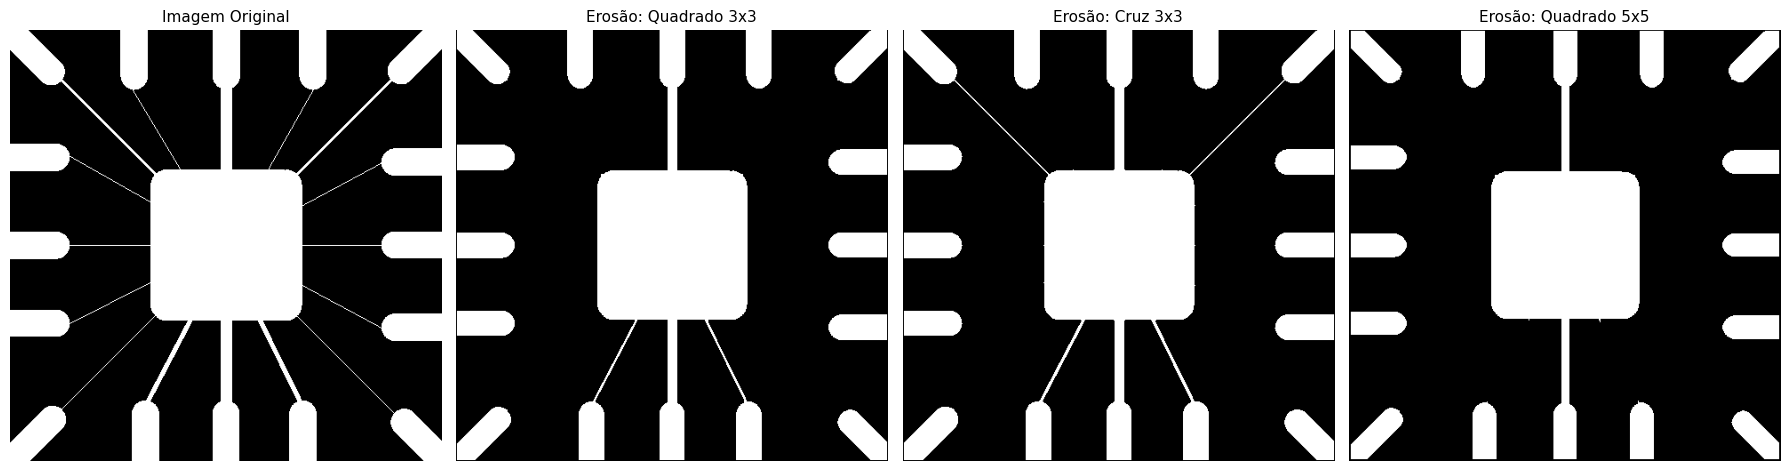

In [ ]:
# CARREGAMENTO DA IMAGEM
img1 = cv2.imread('/content/Fig0905(a)(wirebond-mask).tif', 0)

if img1 is None:
    raise FileNotFoundError("Não foi possível carregar a imagem 1.")


# FUNÇÃO PARA BINARIZAR A IMAGEM
# Converte os pixels para preto (0) ou branco (255)
def binarizar_imagem(img, inverter=False):

    tipo = cv2.THRESH_BINARY_INV if inverter else cv2.THRESH_BINARY

    _, img_binaria = cv2.threshold(img, 127, 255, tipo)

    return img_binaria


# FUNÇÃO PARA CRIAR ELEMENTOS ESTRUTURANTES
# Permite diferentes tamanhos e formas
def criar_elemento_estruturante(tamanho, forma="quadrado"):

    if tamanho < 1 or tamanho % 2 == 0:
        raise ValueError("O tamanho deve ser ímpar e positivo.")

    elemento = np.zeros((tamanho, tamanho), dtype=np.uint8)
    centro = tamanho // 2

    if forma == "quadrado":
        elemento[:, :] = 1

    elif forma == "cruz":
        elemento[centro, :] = 1
        elemento[:, centro] = 1

    elif forma == "disco":
        for i in range(tamanho):
            for j in range(tamanho):

                distancia = (i - centro)**2 + (j - centro)**2

                if distancia <= centro**2:
                    elemento[i, j] = 1

    else:
        raise ValueError("Forma não reconhecida.")

    return elemento


# FUNÇÃO DE EROSÃO MORFOLÓGICA MANUAL
# Percorre cada pixel e verifica sua vizinhança
# conforme as posições ativas do elemento estruturante
def aplicar_erosao(img, elemento):

    img_height, img_width = img.shape
    k_height, k_width = elemento.shape

    # Calcula o padding necessário
    pad_height = k_height // 2
    pad_width = k_width // 2

    # Adiciona bordas pretas ao redor da imagem
    padded_img = np.pad(
        img,
        ((pad_height, pad_height), (pad_width, pad_width)),
        mode='constant',
        constant_values=0
    )

    # Cria a matriz que receberá a imagem processada
    output = np.zeros((img_height, img_width), dtype=np.uint8)

    # Percorre cada pixel da imagem original
    for i_img in range(img_height):
        for j_img in range(img_width):

            manter_pixel = True

            # Percorre o elemento estruturante
            for i_kernel in range(k_height):
                for j_kernel in range(k_width):

                    # Considera apenas as posições ativas
                    if elemento[i_kernel, j_kernel] == 1:

                        pixel = padded_img[
                            i_img + i_kernel,
                            j_img + j_kernel
                        ]

                        # Se algum pixel da vizinhança for preto,
                        # o pixel central será removido
                        if pixel == 0:
                            manter_pixel = False
                            break

                if not manter_pixel:
                    break

            # Mantém o pixel branco somente se todas
            # as posições ativas estiverem sobre pixels brancos
            if manter_pixel:
                output[i_img, j_img] = 255

    return output


# FUNÇÃO PARA EXIBIR OS RESULTADOS
def exibir_resultados_erosao(original, resultados):

    fig, axes = plt.subplots(1, 4, figsize=(18, 6))

    # Imagem original
    axes[0].imshow(original, cmap='gray', vmin=0, vmax=255)
    axes[0].set_title("Imagem Original", fontsize=11)
    axes[0].axis('off')

    # Imagens processadas
    for indice, (nome, imagem) in enumerate(resultados.items(), 1):

        axes[indice].imshow(
            imagem,
            cmap='gray',
            vmin=0,
            vmax=255
        )

        axes[indice].set_title(nome, fontsize=11)
        axes[indice].axis('off')

    plt.tight_layout()
    plt.show()


# APLICAÇÃO DA EROSÃO
# Testa três elementos estruturantes diferentes
def executar_experimento_erosao(img):

    # Binariza a imagem
    img_binaria = binarizar_imagem(img, inverter=False)

    # Criação dos elementos estruturantes
    kernel_quadrado_3x3 = criar_elemento_estruturante(3, "quadrado")
    kernel_cruz_3x3 = criar_elemento_estruturante(3, "cruz")
    kernel_quadrado_5x5 = criar_elemento_estruturante(5, "quadrado")

    # Aplicação da erosão
    print("Iniciando erosão com elemento quadrado 3x3...")
    img_erosao_3x3 = aplicar_erosao(img_binaria, kernel_quadrado_3x3)

    print("Iniciando erosão com elemento cruz 3x3...")
    img_erosao_cruz = aplicar_erosao(img_binaria, kernel_cruz_3x3)

    print("Iniciando erosão com elemento quadrado 5x5...")
    img_erosao_5x5 = aplicar_erosao(img_binaria, kernel_quadrado_5x5)

    print("Erosão concluída! Gerando visualização...")

    # Organiza os resultados
    resultados = {
        "Erosão: Quadrado 3x3": img_erosao_3x3,
        "Erosão: Cruz 3x3": img_erosao_cruz,
        "Erosão: Quadrado 5x5": img_erosao_5x5
    }

    # Exibe a comparação
    exibir_resultados_erosao(img_binaria, resultados)

    return img_binaria, resultados


# EXECUÇÃO
img1_binaria, resultados_erosao = executar_experimento_erosao(img1)

# 2. Dilatação Morfológica

## Justificativa da implementação

A dilatação morfológica é uma operação utilizada para expandir regiões de primeiro plano em imagens binárias, permitindo aumentar a espessura das estruturas, preencher pequenas lacunas e conectar componentes próximos.

Diferentemente da erosão, que reduz as regiões brancas, a dilatação acrescenta pixels às bordas dos objetos. Seu funcionamento depende de um elemento estruturante que determina o tamanho e a forma da vizinhança analisada. Na dilatação binária, um pixel passa a ser branco quando pelo menos uma das posições ativas do elemento estruturante encontra um pixel pertencente ao primeiro plano.

Serão utilizados três elementos estruturantes:

- **Quadrado 3×3:** para avaliar o preenchimento de pequenas lacunas e o aumento da espessura das estruturas.
- **Cruz 3×3:** para observar como a forma do elemento estruturante influencia a expansão das regiões.
- **Quadrado 5×5:** para verificar o efeito de uma dilatação mais intensa sobre as conexões e a preservação dos detalhes.

O objetivo é comparar como o tamanho e a forma do elemento estruturante influenciam o preenchimento das lacunas, a espessura dos caracteres e a possível união de regiões que originalmente estavam separadas.



Iniciando dilatação com elemento quadrado 3x3...
Iniciando dilatação com elemento cruz 3x3...
Iniciando dilatação com elemento quadrado 5x5...
Dilatação concluída! Gerando visualização...


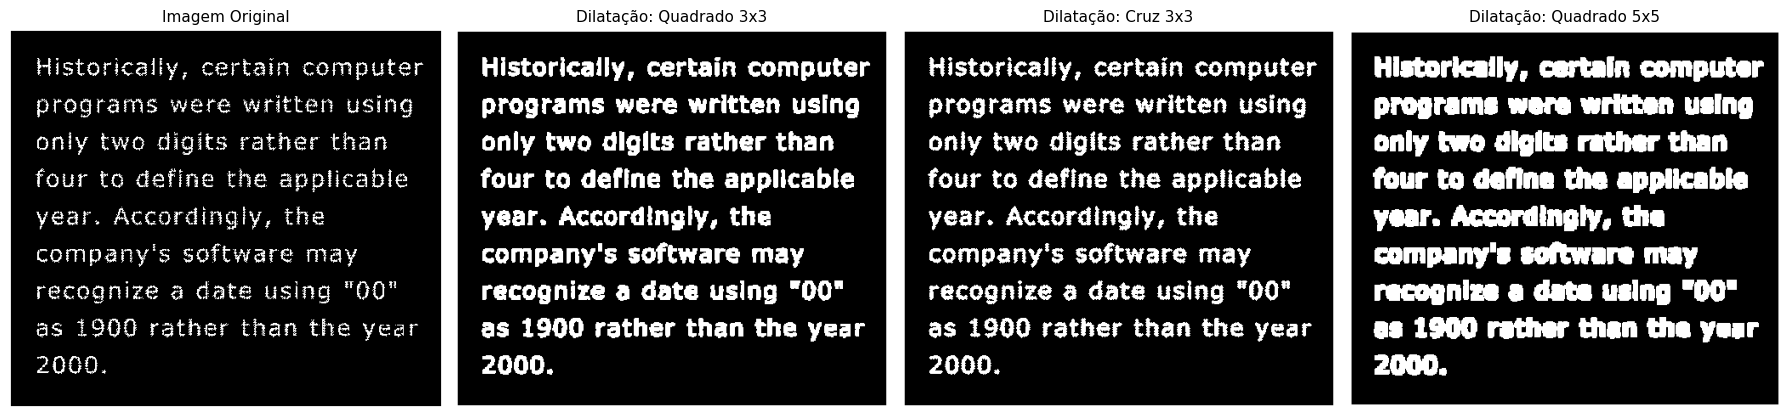

In [ ]:
# CARREGAMENTO DA IMAGEM
img2 = cv2.imread('/content/Fig0907(a)(text_gaps_1_and_2_pixels).tif', 0)

if img2 is None:
    raise FileNotFoundError("Não foi possível carregar a imagem 2.")


# FUNÇÃO DE DILATAÇÃO MORFOLÓGICA MANUAL
# Percorre cada pixel e verifica sua vizinhança
# conforme as posições ativas do elemento estruturante
def aplicar_dilatacao(img, elemento):

    img_height, img_width = img.shape
    k_height, k_width = elemento.shape

    # Calcula o padding necessário
    pad_height = k_height // 2
    pad_width = k_width // 2

    # Adiciona bordas pretas ao redor da imagem
    padded_img = np.pad(
        img,
        ((pad_height, pad_height), (pad_width, pad_width)),
        mode='constant',
        constant_values=0
    )

    # Cria a matriz que receberá a imagem processada
    output = np.zeros((img_height, img_width), dtype=np.uint8)

    # Reflete o elemento estruturante para a dilatação
    elemento_refletido = np.flip(elemento, axis=(0, 1))

    # Percorre cada pixel da imagem original
    for i_img in range(img_height):
        for j_img in range(img_width):

            dilatar_pixel = False

            # Percorre o elemento estruturante
            for i_kernel in range(k_height):
                for j_kernel in range(k_width):

                    # Considera apenas as posições ativas
                    if elemento_refletido[i_kernel, j_kernel] == 1:

                        pixel = padded_img[
                            i_img + i_kernel,
                            j_img + j_kernel
                        ]

                        # Se algum pixel da vizinhança for branco,
                        # o pixel central será branco
                        if pixel == 255:
                            dilatar_pixel = True
                            break

                if dilatar_pixel:
                    break

            # Adiciona o pixel branco quando encontra
            # pelo menos uma posição ativa sobre um pixel branco
            if dilatar_pixel:
                output[i_img, j_img] = 255

    return output


# FUNÇÃO PARA EXIBIR OS RESULTADOS
def exibir_resultados_dilatacao(original, resultados):

    fig, axes = plt.subplots(1, 4, figsize=(18, 6))

    # Imagem original
    axes[0].imshow(original, cmap='gray', vmin=0, vmax=255)
    axes[0].set_title("Imagem Original", fontsize=11)
    axes[0].axis('off')

    # Imagens processadas
    for indice, (nome, imagem) in enumerate(resultados.items(), 1):

        axes[indice].imshow(
            imagem,
            cmap='gray',
            vmin=0,
            vmax=255
        )

        axes[indice].set_title(nome, fontsize=11)
        axes[indice].axis('off')

    plt.tight_layout()
    plt.show()


# APLICAÇÃO DA DILATAÇÃO
# Testa três elementos estruturantes diferentes
def executar_experimento_dilatacao(img):

    # Binariza a imagem
    img_binaria = binarizar_imagem(img, inverter=False)

    # Criação dos elementos estruturantes
    kernel_quadrado_3x3 = criar_elemento_estruturante(3, "quadrado")
    kernel_cruz_3x3 = criar_elemento_estruturante(3, "cruz")
    kernel_quadrado_5x5 = criar_elemento_estruturante(5, "quadrado")

    # Aplicação da dilatação
    print("Iniciando dilatação com elemento quadrado 3x3...")
    img_dilatacao_3x3 = aplicar_dilatacao(
        img_binaria, kernel_quadrado_3x3
    )

    print("Iniciando dilatação com elemento cruz 3x3...")
    img_dilatacao_cruz = aplicar_dilatacao(
        img_binaria, kernel_cruz_3x3
    )

    print("Iniciando dilatação com elemento quadrado 5x5...")
    img_dilatacao_5x5 = aplicar_dilatacao(
        img_binaria, kernel_quadrado_5x5
    )

    print("Dilatação concluída! Gerando visualização...")

    # Organiza os resultados
    resultados = {
        "Dilatação: Quadrado 3x3": img_dilatacao_3x3,
        "Dilatação: Cruz 3x3": img_dilatacao_cruz,
        "Dilatação: Quadrado 5x5": img_dilatacao_5x5
    }

    # Exibe a comparação
    exibir_resultados_dilatacao(img_binaria, resultados)

    return img_binaria, resultados


# EXECUÇÃO
img2_binaria, resultados_dilatacao = executar_experimento_dilatacao(img2)

# 3. Análise dos Resultados — Erosão e Dilatação

## 3.1 Análise da Erosão Morfológica

A aplicação da erosão morfológica demonstrou como o tamanho e a forma do elemento estruturante influenciam diretamente a preservação das estruturas da imagem.

**Erosão com quadrado 3×3:** A aplicação gerou uma redução nas bordas dos componentes brancos, diminuindo ligeiramente o tamanho da região central e dos terminais externos. As conexões mais finas foram removidas em grande parte, causando a perda de informações importantes e a separação de alguns componentes que anteriormente estavam conectados.

**Erosão com cruz 3×3:** Apresentou um comportamento menos agressivo em comparação ao quadrado 3×3. Como o elemento estruturante considera apenas os vizinhos horizontais e verticais, houve a preservação de algumas conexões finas, inclusive diagonais. A região central também sofreu redução, mas uma quantidade maior de detalhes foi mantida.

**Erosão com quadrado 5×5:** Produziu a maior redução das estruturas. As conexões mais finas desapareceram, enquanto a região central e os terminais externos sofreram uma diminuição mais acentuada. Esse resultado demonstra que elementos estruturantes maiores podem eliminar detalhes importantes da imagem, comprometendo a continuidade entre seus componentes.

De maneira geral, os resultados mostram que a erosão é eficiente para reduzir regiões e eliminar estruturas mais finas, porém sua aplicação pode causar perda de informação. Entre as configurações testadas, a cruz 3×3 apresentou maior preservação das conexões, enquanto o quadrado 5×5 provocou a maior degradação estrutural. Portanto, a escolha do elemento estruturante deve considerar as características da imagem e o objetivo do processamento.

## 3.2 Análise da Dilatação Morfológica

A aplicação da dilatação morfológica demonstrou como o tamanho e a forma do elemento estruturante influenciam o preenchimento de pequenas falhas e a espessura dos caracteres.

**Dilatação com quadrado 3×3:** A aplicação provocou um aumento perceptível na espessura das letras, preenchendo pequenas descontinuidades presentes na imagem original. Os caracteres ficaram mais destacados e visualmente contínuos. Entretanto, algumas regiões internas das letras ficaram reduzidas, e traços próximos começaram a se unir, causando uma leve perda de definição.

**Dilatação com cruz 3×3:** Apresentou um comportamento mais moderado em comparação ao quadrado 3×3. A expansão dos caracteres foi suficiente para reduzir pequenas falhas, mantendo melhor os espaços internos e a separação entre os traços. Como resultado, o texto apresentou um equilíbrio maior entre o preenchimento das descontinuidades e a preservação da legibilidade.

**Dilatação com quadrado 5×5:** Produziu a expansão mais intensa dos caracteres, preenchendo lacunas maiores, mas também causando a união indesejada de regiões próximas. Diversas letras ficaram excessivamente espessas, com espaços internos reduzidos ou muito preenchidos. Esse comportamento comprometeu a definição dos caracteres e dificultou a leitura de algumas palavras.

De maneira geral, os resultados demonstram que a dilatação pode melhorar a continuidade de estruturas que apresentam pequenas interrupções, mas sua aplicação excessiva pode comprometer a qualidade visual. Entre as configurações testadas, a cruz 3×3 apresentou o melhor equilíbrio entre preenchimento das falhas e preservação dos caracteres, enquanto o quadrado 5×5 provocou a maior perda de definição. Portanto, a escolha do elemento estruturante deve considerar a dimensão das lacunas que se deseja preencher e a necessidade de preservar os detalhes da imagem.

## 3.3 Comparação entre Erosão e Dilatação

Os experimentos demonstraram comportamentos opostos entre as operações morfológicas. Enquanto a erosão reduziu as regiões brancas, diminuindo a espessura das estruturas e provocando o rompimento de conexões finas, a dilatação expandiu essas regiões, aumentando a espessura dos caracteres e preenchendo pequenas lacunas.

Em ambos os casos, o tamanho e a forma do elemento estruturante influenciaram diretamente os resultados. Os elementos quadrados 5×5 produziram alterações mais intensas, causando maior perda de informações na erosão e maior união indesejada de estruturas na dilatação. Já os elementos em cruz 3×3 apresentaram resultados mais moderados, preservando uma quantidade maior de detalhes nas duas aplicações.

Dessa forma, observou-se que nenhuma das operações garante, isoladamente, uma melhoria na qualidade visual. A eficácia de cada técnica depende das características da imagem, do tamanho e da forma do elemento estruturante e, principalmente, do objetivo do processamento.

# 4. Detecção de Bordas — Sobel

## Justificativa da escolha

Para analisar a influência das operações morfológicas sobre os contornos da imagem, foi escolhido o operador Sobel, que é uma técnica de detecção de bordas baseada no cálculo das variações de intensidade dos pixels nas direções horizontal e vertical.

O Sobel utiliza duas máscaras de tamanho 3×3 para calcular os gradientes da imagem. A combinação desses gradientes permite identificar regiões onde ocorrem mudanças significativas de intensidade, destacando os contornos dos objetos.

A escolha do Sobel se deve à sua capacidade de detectar bordas em diferentes orientações, permitindo observar como a erosão e a dilatação modificam os limites das estruturas presentes na imagem.

Será aplicado o detector de bordas em três situações:

- **Imagem original:** para identificar os contornos das estruturas antes das operações morfológicas.
- **Após a erosão:** para verificar como a redução das regiões e a remoção de conexões finas influenciam a detecção das bordas.
- **Após a dilatação:** para observar como a expansão das estruturas e a união de componentes próximos modificam seus contornos.

Para manter as condições de comparação, serão utilizadas as funções de erosão e dilatação desenvolvidas anteriormente, ambas com elemento estruturante quadrado 3×3.

O objetivo é comparar visualmente os contornos detectados antes e depois dos processamentos morfológicos, avaliando possíveis alterações nas bordas, a preservação das conexões e a perda ou o surgimento de detalhes.



Aplicando Sobel na imagem original...
Aplicando erosão e detecção de bordas...
Aplicando dilatação e detecção de bordas...
Processamento concluído! Gerando comparação...


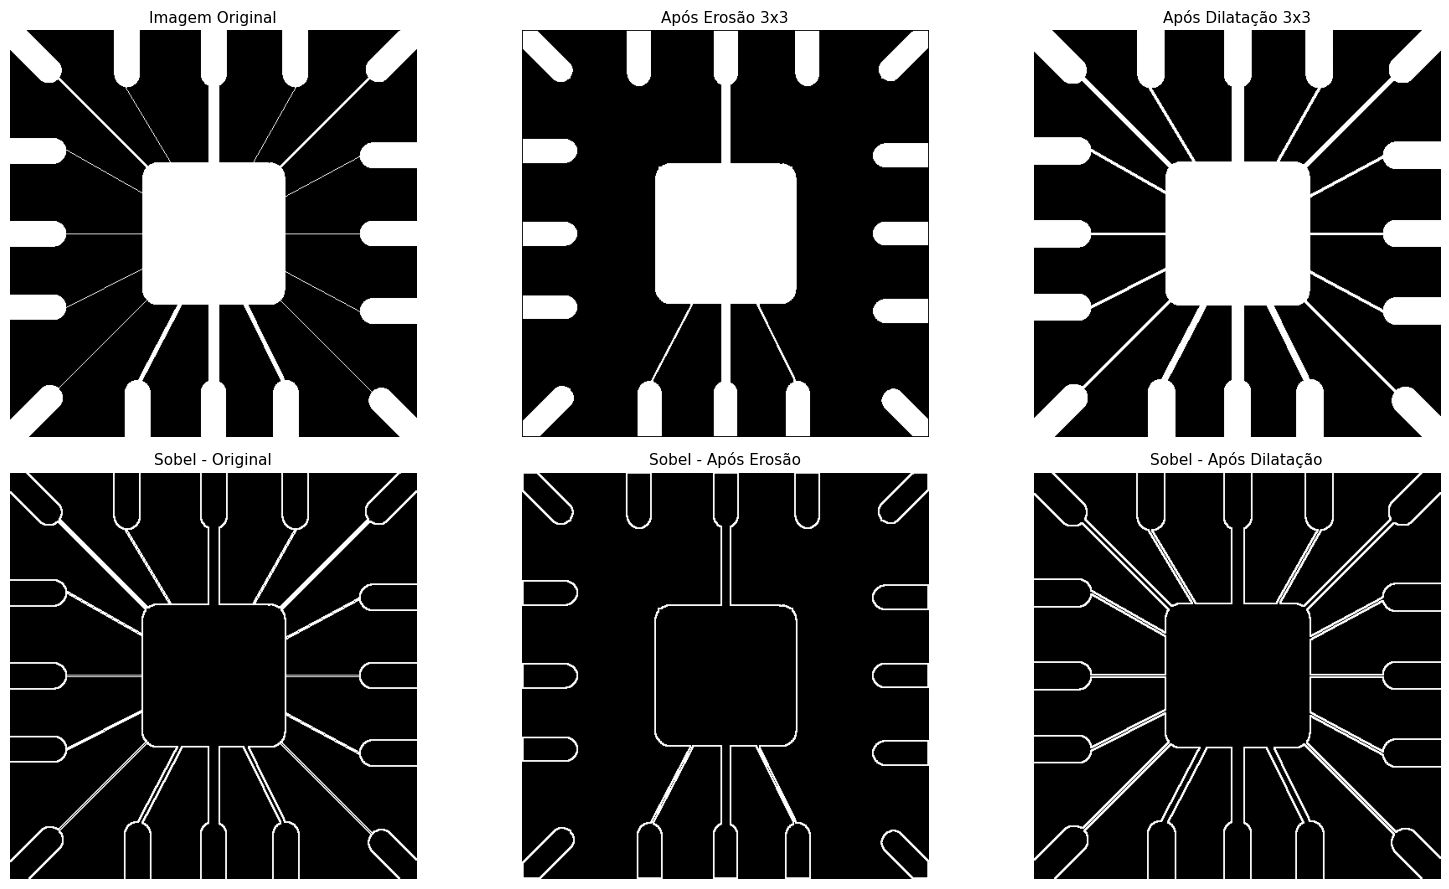

In [ ]:
# FUNÇÃO DE DETECÇÃO DE BORDAS COM SOBEL
def aplicar_sobel(img):

    img_height, img_width = img.shape

    # Máscara para detectar variações horizontais
    kernel_x = np.array([
        [-1,  0,  1],
        [-2,  0,  2],
        [-1,  0,  1]
    ])

    # Máscara para detectar variações verticais
    kernel_y = np.array([
        [-1, -2, -1],
        [ 0,  0,  0],
        [ 1,  2,  1]
    ])

    # Adiciona padding para processar as extremidades
    padded_img = np.pad(
        img,
        ((1, 1), (1, 1)),
        mode='edge'
    )

    # Cria a matriz que receberá as bordas detectadas
    output = np.zeros((img_height, img_width), dtype=np.uint8)

    # Percorre cada pixel da imagem
    for i_img in range(img_height):
        for j_img in range(img_width):

            grad_x = 0
            grad_y = 0

            # Percorre as máscaras do Sobel
            for i_kernel in range(3):
                for j_kernel in range(3):

                    pixel = int(padded_img[
                        i_img + i_kernel,
                        j_img + j_kernel
                    ])

                    # Calcula os gradientes horizontal e vertical
                    grad_x += pixel * kernel_x[i_kernel, j_kernel]
                    grad_y += pixel * kernel_y[i_kernel, j_kernel]

            # Calcula a magnitude do gradiente
            magnitude = np.sqrt(grad_x**2 + grad_y**2)

            # Limita o resultado ao intervalo de 0 a 255
            output[i_img, j_img] = min(255, int(magnitude))

    return output


# FUNÇÃO PARA EXIBIR OS RESULTADOS
def exibir_resultados_sobel(imagens, bordas):

    fig, axes = plt.subplots(2, 3, figsize=(16, 9))

    titulos_imagens = [
        "Imagem Original",
        "Após Erosão 3x3",
        "Após Dilatação 3x3"
    ]

    titulos_bordas = [
        "Sobel - Original",
        "Sobel - Após Erosão",
        "Sobel - Após Dilatação"
    ]

    # Primeira linha: imagens antes do Sobel
    for i in range(3):
        axes[0, i].imshow(
            imagens[i],
            cmap='gray',
            vmin=0,
            vmax=255
        )
        axes[0, i].set_title(titulos_imagens[i], fontsize=11)
        axes[0, i].axis('off')

    # Segunda linha: bordas detectadas pelo Sobel
    for i in range(3):
        axes[1, i].imshow(
            bordas[i],
            cmap='gray',
            vmin=0,
            vmax=255
        )
        axes[1, i].set_title(titulos_bordas[i], fontsize=11)
        axes[1, i].axis('off')

    plt.tight_layout()
    plt.show()


# APLICAÇÃO DO SOBEL ANTES E DEPOIS DAS OPERAÇÕES MORFOLÓGICAS
def executar_experimento_sobel(img):

    # Elemento estruturante quadrado 3x3
    kernel_3x3 = criar_elemento_estruturante(3, "quadrado")

    # ETAPA 1: DETECÇÃO NA IMAGEM ORIGINAL
    print("Aplicando Sobel na imagem original...")
    img_sobel_original = aplicar_sobel(img)

    # ETAPA 2: EROSÃO + SOBEL
    print("Aplicando erosão e detecção de bordas...")
    img_erodida = aplicar_erosao(img, kernel_3x3)
    img_sobel_erosao = aplicar_sobel(img_erodida)

    # ETAPA 3: DILATAÇÃO + SOBEL
    print("Aplicando dilatação e detecção de bordas...")
    img_dilatada = aplicar_dilatacao(img, kernel_3x3)
    img_sobel_dilatacao = aplicar_sobel(img_dilatada)

    print("Processamento concluído! Gerando comparação...")

    # Organiza as imagens
    imagens = [
        img,
        img_erodida,
        img_dilatada
    ]

    bordas = [
        img_sobel_original,
        img_sobel_erosao,
        img_sobel_dilatacao
    ]

    # Exibe os resultados
    exibir_resultados_sobel(imagens, bordas)

    return imagens, bordas


# EXECUÇÃO
imagens_sobel, resultados_sobel = executar_experimento_sobel(img1_binaria)

## Análise dos resultados

A aplicação do operador Sobel permitiu visualizar as alterações provocadas pela erosão e pela dilatação nos contornos da imagem escolhida, evidenciando diferenças na preservação das conexões e na definição das bordas.

**Sobel na imagem original:** O operador conseguiu identificar os contornos da região central, dos terminais externos e das conexões que os interligam. As linhas mais finas e diagonais também foram detectadas, permitindo visualizar a estrutura original do circuito. Como a imagem apresenta regiões bem definidas entre preto e branco, as bordas foram destacadas com boa nitidez.

**Sobel após a erosão 3×3:** A redução das regiões brancas provocou mudanças significativas nos contornos detectados. Diversas conexões finas desapareceram, principalmente as linhas diagonais, fazendo com que o Sobel deixasse de identificar algumas ligações presentes na imagem original. A região central e os terminais externos continuaram com as bordas bem definidas, porém com dimensões reduzidas. Esse resultado atesta que a erosão pode simplificar os contornos, mas também eliminar informações estruturais importantes.

**Sobel após a dilatação 3×3:** A expansão das regiões brancas tornou as conexões mais espessas, fazendo com que seus contornos ficassem mais destacados na detecção de bordas. Diferentemente da erosão, a dilatação preservou as conexões finas e ampliou seus limites, produzindo contornos em posições mais externas. Entretanto, essa expansão também modificou as dimensões originais das estruturas e aproximou bordas de componentes próximos.

De maneira geral, os resultados demonstram que as operações morfológicas influenciam diretamente a detecção de bordas. A erosão reduziu a quantidade de contornos ao eliminar conexões finas, enquanto a dilatação aumentou a espessura das estruturas e destacou seus limites externos.

Entre as configurações avaliadas, a aplicação do Sobel diretamente na imagem original apresentou a melhor preservação das informações estruturais. A erosão ocasionou perda de conexões importantes, enquanto a dilatação manteve essas ligações, mas alterou suas dimensões. Portanto, a utilização de operações morfológicas antes da detecção de bordas deve considerar o objetivo do processamento, pois pode tanto facilitar a identificação de determinadas estruturas quanto comprometer a fidelidade dos contornos originais.



# 5. Abertura Morfológica

## Justificativa da implementação

A abertura morfológica é uma operação utilizada para remover pequenas estruturas, eliminar conexões estreitas e suavizar os contornos dos objetos em imagens binárias.

Seu funcionamento consiste na aplicação de duas operações em sequência: primeiro a erosão, que reduz as regiões brancas e remove estruturas menores que o elemento estruturante, seguida da dilatação, que expande as regiões restantes, recuperando parcialmente suas dimensões sem restaurar os detalhes eliminados.
Serão utilizados três elementos estruturantes:

- **Quadrado 3×3:** para avaliar a remoção de pequenas estruturas e conexões finas.
- **Cruz 3×3:** para observar como a forma do elemento estruturante influencia a preservação dos detalhes.
- **Quadrado 5×5:** para verificar o efeito de uma abertura mais intensa sobre as estruturas da imagem.

O objetivo é comparar como o tamanho e a forma do elemento estruturante influenciam a remoção de detalhes, a suavização dos contornos e a preservação das estruturas maiores da imagem.



Iniciando abertura com elemento quadrado 3x3...
Iniciando abertura com elemento cruz 3x3...
Iniciando abertura com elemento quadrado 5x5...
Abertura concluída! Gerando visualização...


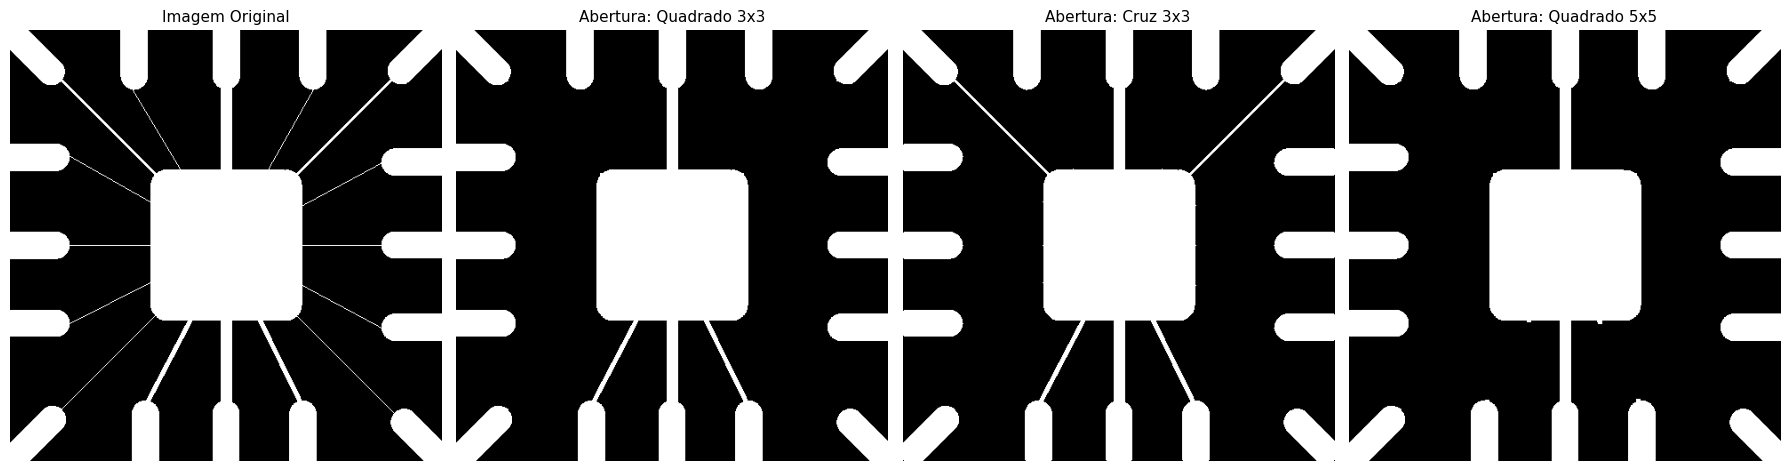

In [ ]:
# FUNÇÃO DE ABERTURA MORFOLÓGICA MANUAL
# Aplica erosão seguida de dilatação
def aplicar_abertura(img, elemento):

    # ETAPA 1: EROSÃO
    # Remove estruturas finas e reduz os objetos
    img_erodida = aplicar_erosao(img, elemento)

    # ETAPA 2: DILATAÇÃO
    # Expande as estruturas restantes
    img_abertura = aplicar_dilatacao(img_erodida, elemento)

    return img_abertura


# FUNÇÃO PARA EXIBIR OS RESULTADOS
def exibir_resultados_abertura(original, resultados):

    fig, axes = plt.subplots(1, 4, figsize=(18, 6))

    # Imagem original
    axes[0].imshow(original, cmap='gray', vmin=0, vmax=255)
    axes[0].set_title("Imagem Original", fontsize=11)
    axes[0].axis('off')

    # Imagens processadas
    for indice, (nome, imagem) in enumerate(resultados.items(), 1):

        axes[indice].imshow(
            imagem,
            cmap='gray',
            vmin=0,
            vmax=255
        )

        axes[indice].set_title(nome, fontsize=11)
        axes[indice].axis('off')

    plt.tight_layout()
    plt.show()


# APLICAÇÃO DA ABERTURA
# Testa três elementos estruturantes diferentes
def executar_experimento_abertura(img):

    # Criação dos elementos estruturantes
    kernel_quadrado_3x3 = criar_elemento_estruturante(3, "quadrado")
    kernel_cruz_3x3 = criar_elemento_estruturante(3, "cruz")
    kernel_quadrado_5x5 = criar_elemento_estruturante(5, "quadrado")

    # Aplicação da abertura
    print("Iniciando abertura com elemento quadrado 3x3...")
    img_abertura_3x3 = aplicar_abertura(
        img, kernel_quadrado_3x3
    )

    print("Iniciando abertura com elemento cruz 3x3...")
    img_abertura_cruz = aplicar_abertura(
        img, kernel_cruz_3x3
    )

    print("Iniciando abertura com elemento quadrado 5x5...")
    img_abertura_5x5 = aplicar_abertura(
        img, kernel_quadrado_5x5
    )

    print("Abertura concluída! Gerando visualização...")

    # Organiza os resultados
    resultados = {
        "Abertura: Quadrado 3x3": img_abertura_3x3,
        "Abertura: Cruz 3x3": img_abertura_cruz,
        "Abertura: Quadrado 5x5": img_abertura_5x5
    }

    # Exibe a comparação
    exibir_resultados_abertura(img, resultados)

    return resultados


# EXECUÇÃO
# Reutilizando a imagem binarizada do Item 1
resultados_abertura = executar_experimento_abertura(img1_binaria)

## Análise dos resultados

A aplicação da abertura morfológica demonstrou como a combinação da erosão seguida da dilatação permite remover estruturas finas, preservando parcialmente as dimensões dos componentes maiores da imagem.

**Abertura com quadrado 3×3:** A aplicação provocou a remoção de grande parte das conexões finas, principalmente das linhas diagonais que ligavam a região central aos terminais externos. Entretanto, a dilatação realizada após a erosão permitiu recuperar parte das dimensões das estruturas restantes, mantendo a região central e os terminais bem definidos. O resultado apresentou uma imagem mais simplificada, porém com perda de informações importantes sobre as conexões.

**Abertura com cruz 3×3:** Apresentou um comportamento menos agressivo em comparação ao quadrado 3×3. Como o elemento estruturante considera apenas os vizinhos horizontais e verticais, algumas conexões diagonais foram preservadas. A região central e os terminais externos mantiveram dimensões próximas às originais, enquanto parte das estruturas mais finas foi eliminada. Essa configuração apresentou o melhor equilíbrio entre a remoção de detalhes e a preservação das conexões.

**Abertura com quadrado 5×5:** Produziu a remoção mais intensa das estruturas finas. As conexões diagonais desapareceram praticamente por completo, permanecendo principalmente a região central, os terminais externos e algumas conexões mais espessas. Embora a dilatação tenha recuperado parcialmente as dimensões dos componentes restantes, as estruturas eliminadas durante a erosão não foram restauradas, resultando em uma perda significativa de informações.

De maneira geral, os resultados demonstram que a abertura morfológica é eficiente para remover estruturas pequenas e suavizar os contornos dos objetos, sem provocar uma redução tão acentuada das regiões maiores quanto a erosão isolada. Entretanto, sua aplicação também pode eliminar conexões importantes quando estas apresentam espessura inferior à área de atuação do elemento estruturante.

Entre as configurações testadas, a cruz 3×3 apresentou maior preservação dos detalhes, enquanto o quadrado 5×5 provocou a maior perda de informação estrutural. Portanto, a escolha do elemento estruturante deve considerar o tamanho das estruturas que se deseja remover e a necessidade de preservar os componentes relevantes da imagem.



# 6. Fechamento Morfológico

## Justificativa da implementação

O fechamento morfológico é uma operação utilizada para preencher pequenas lacunas, conectar as estruturas próximas e suavizar os contornos dos objetos em imagens binárias.

Seu funcionamento consiste na aplicação de duas operações em sequência: primeiro a dilatação, que expande as regiões brancas e permite preencher pequenos espaços, seguida da erosão, que reduz as regiões expandidas, recuperando de forma parcial as dimensões originais dos objetos sem necessariamente reabrir as lacunas já preenchidas.

Serão utilizados três elementos estruturantes:

- **Quadrado 3×3:** para avaliar o preenchimento de pequenas lacunas e a conexão de estruturas próximas.
- **Cruz 3×3:** para observar como a forma do elemento estruturante influencia a união das regiões e a preservação dos contornos.
- **Quadrado 5×5:** para verificar o efeito de um fechamento mais intenso sobre o preenchimento dos espaços e a possível união indesejada de componentes.

O objetivo é avaliar como o tamanho e a forma do elemento estruturante influenciam o preenchimento de lacunas, a união de componentes próximos e a preservação das características originais da imagem.



Iniciando fechamento com elemento quadrado 3x3...
Iniciando fechamento com elemento cruz 3x3...
Iniciando fechamento com elemento quadrado 5x5...
Fechamento concluído! Gerando visualização...


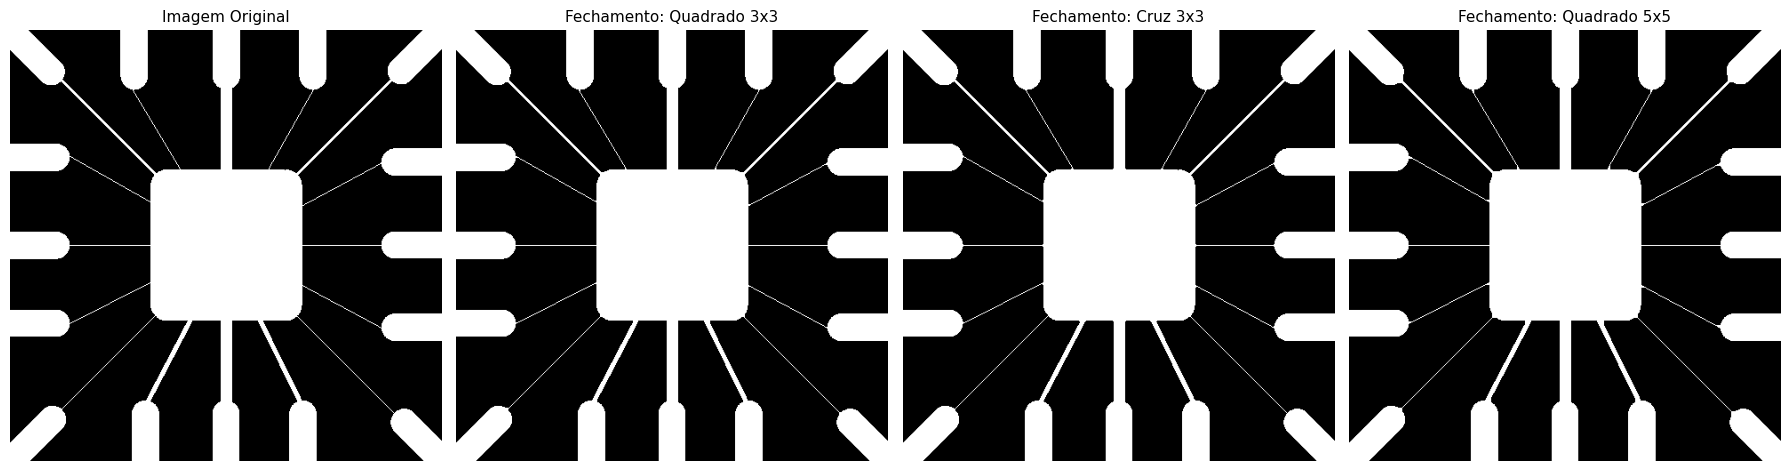

In [ ]:
# FUNÇÃO DE FECHAMENTO MORFOLÓGICO MANUAL
# Aplica dilatação seguida de erosão
def aplicar_fechamento(img, elemento):

    # Adiciona uma borda temporária para evitar
    # a perda artificial de pixels nas extremidades
    # durante a erosão
    pad_height = elemento.shape[0] // 2
    pad_width = elemento.shape[1] // 2

    img_padded = np.pad(
        img,
        ((pad_height, pad_height), (pad_width, pad_width)),
        mode='constant',
        constant_values=0
    )

    # ETAPA 1: DILATAÇÃO
    # Expande os objetos e preenche pequenas lacunas
    img_dilatada = aplicar_dilatacao(img_padded, elemento)

    # ETAPA 2: EROSÃO
    # Reduz as regiões expandidas preservando as conexões formadas
    img_fechamento = aplicar_erosao(img_dilatada, elemento)

    # Remove a borda temporária e retorna a imagem com suas dimensões originais
    img_fechamento = img_fechamento[
        pad_height:pad_height + img.shape[0],
        pad_width:pad_width + img.shape[1]
    ]

    return img_fechamento


# FUNÇÃO PARA EXIBIR OS RESULTADOS
def exibir_resultados_fechamento(original, resultados):

    fig, axes = plt.subplots(1, 4, figsize=(18, 6))

    # Imagem original
    axes[0].imshow(original, cmap='gray', vmin=0, vmax=255)
    axes[0].set_title("Imagem Original", fontsize=11)
    axes[0].axis('off')

    # Imagens processadas
    for indice, (nome, imagem) in enumerate(resultados.items(), 1):

        axes[indice].imshow(
            imagem,
            cmap='gray',
            vmin=0,
            vmax=255
        )

        axes[indice].set_title(nome, fontsize=11)
        axes[indice].axis('off')

    plt.tight_layout()
    plt.show()


# APLICAÇÃO DO FECHAMENTO
# Testa três elementos estruturantes diferentes
def executar_experimento_fechamento(img):

    # Criação dos elementos estruturantes
    kernel_quadrado_3x3 = criar_elemento_estruturante(3, "quadrado")
    kernel_cruz_3x3 = criar_elemento_estruturante(3, "cruz")
    kernel_quadrado_5x5 = criar_elemento_estruturante(5, "quadrado")

    # Aplicação do fechamento
    print("Iniciando fechamento com elemento quadrado 3x3...")
    img_fechamento_3x3 = aplicar_fechamento(
        img, kernel_quadrado_3x3
    )

    print("Iniciando fechamento com elemento cruz 3x3...")
    img_fechamento_cruz = aplicar_fechamento(
        img, kernel_cruz_3x3
    )

    print("Iniciando fechamento com elemento quadrado 5x5...")
    img_fechamento_5x5 = aplicar_fechamento(
        img, kernel_quadrado_5x5
    )

    print("Fechamento concluído! Gerando visualização...")

    # Organiza os resultados
    resultados = {
        "Fechamento: Quadrado 3x3": img_fechamento_3x3,
        "Fechamento: Cruz 3x3": img_fechamento_cruz,
        "Fechamento: Quadrado 5x5": img_fechamento_5x5
    }

    # Exibe a comparação
    exibir_resultados_fechamento(img, resultados)

    return resultados


# EXECUÇÃO
# Reutilizando a imagem binarizada do Item 1
resultados_fechamento = executar_experimento_fechamento(img1_binaria)

## Análise dos resultados

A aplicação do fechamento morfológico demonstrou como a combinação da dilatação seguida da erosão permite preencher pequenas lacunas e suavizar os contornos, preservando grande parte das estruturas originais da imagem.

**Fechamento com quadrado 3×3:** A aplicação apresentou poucas alterações em relação à imagem original. As conexões finas foram preservadas, enquanto algumas regiões de encontro entre os componentes ficaram ligeiramente mais preenchidas. A dilatação inicial expandiu as estruturas, e a erosão posterior recuperou suas dimensões, mantendo os contornos próximos aos originais.

**Fechamento com cruz 3×3:** Apresentou um comportamento ainda mais próximo da imagem original. Como o elemento estruturante considera apenas os vizinhos horizontais e verticais, a operação provocou alterações menores nas conexões diagonais. A região central, os terminais externos e as linhas de ligação permaneceram bem definidos, demonstrando uma boa preservação das informações estruturais.

**Fechamento com quadrado 5×5:** Produziu alterações um pouco mais perceptíveis, principalmente nas regiões onde as conexões finas encontram os componentes maiores. Algumas dessas regiões ficaram mais preenchidas e seus contornos ligeiramente suavizados. Entretanto, mesmo com um elemento estruturante maior, a imagem manteve praticamente todas as conexões e os componentes presentes originalmente, sem apresentar uma união excessiva entre estruturas distintas.

De maneira geral, os resultados demonstram que o fechamento morfológico preservou a maior parte das informações da imagem, produzindo alterações menos significativas do que as observadas anteriormente na abertura. Isso ocorre porque a imagem original já apresenta conexões contínuas e poucas lacunas que poderiam ser preenchidas pelo processamento.

Entre as configurações testadas, a cruz 3×3 apresentou maior fidelidade visual à imagem original, enquanto o quadrado 5×5 provocou modificações um pouco mais evidentes nos contornos e nas regiões de conexão. Portanto, o fechamento mostrou-se adequado para preservar estruturas e preencher pequenas descontinuidades, embora sua contribuição visual tenha sido limitada pelas características da imagem utilizada.



# 7. Aplicação do Processamento Morfológico — Impressão Digital

## Justificativa da aplicação

Para este experimento, serão aplicadas operações morfológicas de erosão, abertura e fechamento sobre uma imagem de impressão digital com ruídos, seguindo a sequência apresentada no enunciado desta atividade.

A imagem selecionada, apresenta pequenos pontos isolados no fundo e descontinuidades nas linhas da impressão digital, dificultando a identificação de algumas estruturas.

Foi escolhido um elemento estruturante quadrado 3×3, formado por valores iguais a 1, conforme o exemplo de referência. Esse elemento permite atuar sobre pequenas irregularidades da imagem sem utilizar uma vizinhança excessivamente grande.

O processamento será realizado nas seguintes etapas:

- **Erosão:** reduzir as regiões brancas, removendo pequenos pontos isolados, embora também possa eliminar partes das linhas mais finas.
- **Abertura:** aplicar a dilatação após a erosão, recuperando parcialmente a espessura das linhas preservadas sem restaurar os ruídos removidos.
- **Dilatação da imagem aberta:** expandir as linhas restantes para aproximar suas extremidades e preencher pequenas interrupções.
- **Fechamento:** aplicar uma erosão após a dilatação, buscando recuperar as dimensões das linhas enquanto mantém parte das descontinuidades preenchidas.

O objetivo é reproduzir a sequência apresentada no enunciado e avaliar como a combinação dessas operações influencia a remoção de ruídos, a continuidade das linhas e a preservação dos detalhes da impressão digital.


Elemento estruturante utilizado:
[[1 1 1]
 [1 1 1]
 [1 1 1]]

1/4: Aplicando erosão...
2/4: Aplicando abertura...
3/4: Aplicando dilatação na imagem aberta...
4/4: Aplicando fechamento na imagem aberta...
Processamento concluído! Gerando comparação...


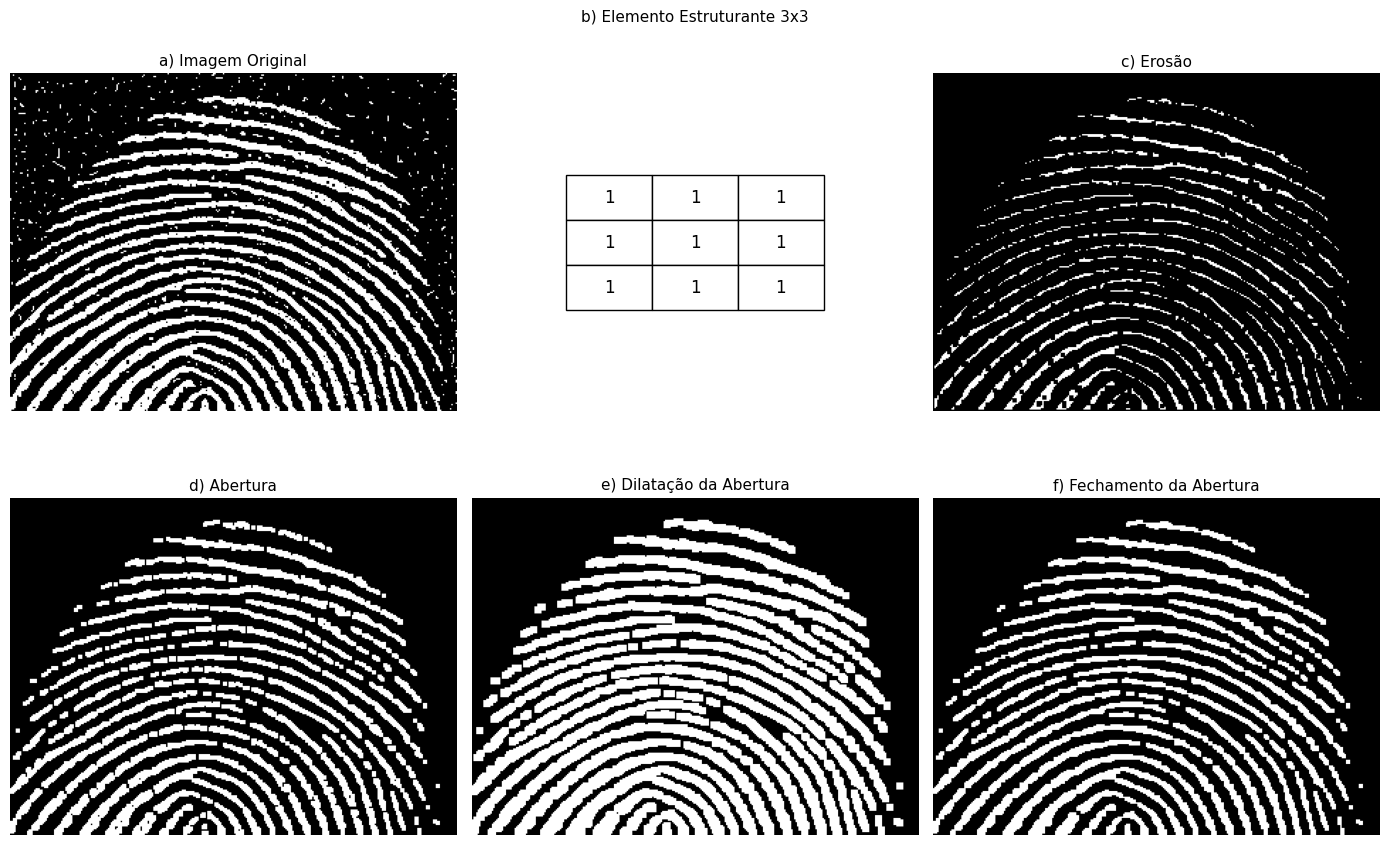

In [ ]:
# FUNÇÃO PARA EXIBIR AS ETAPAS DO PROCESSAMENTO
def exibir_resultados_impressao_digital(etapas, elemento):

    fig, axes = plt.subplots(2, 3, figsize=(14, 9))

    # Lista com as posições e os títulos das imagens
    configuracoes = [
        (0, 0, "a) Imagem Original", "original"),
        (0, 2, "c) Erosão", "erosao"),
        (1, 0, "d) Abertura", "abertura"),
        (1, 1, "e) Dilatação da Abertura", "dilatacao"),
        (1, 2, "f) Fechamento da Abertura", "fechamento")
    ]

    # Exibe as imagens processadas
    for linha, coluna, titulo, chave in configuracoes:

        axes[linha, coluna].imshow(
            etapas[chave],
            cmap='gray',
            vmin=0,
            vmax=255
        )

        axes[linha, coluna].set_title(titulo, fontsize=11)
        axes[linha, coluna].axis('off')

    # Exibe o elemento estruturante utilizado
    axes[0, 1].axis('off')
    axes[0, 1].set_title("b) Elemento Estruturante 3x3", fontsize=11)

    tabela = axes[0, 1].table(
        cellText=elemento.tolist(),
        cellLoc='center',
        loc='center',
        colWidths=[0.16] * elemento.shape[1]
    )

    tabela.auto_set_font_size(False)
    tabela.set_fontsize(12)
    tabela.scale(1.2, 2)

    plt.tight_layout()
    plt.show()


# APLICAÇÃO DO PROCESSAMENTO MORFOLÓGICO
def executar_experimento_impressao_digital(caminho):

    # CARREGAMENTO DA IMAGEM
    # Carrega a impressão digital em escala de cinza
    img = cv2.imread(caminho, 0)

    if img is None:
        raise FileNotFoundError(
            "Não foi possível carregar a imagem da impressão digital."
        )

    # Binarização da imagem
    img_binaria = binarizar_imagem(img, inverter=False)

    # ELEMENTO ESTRUTURANTE
    elemento = criar_elemento_estruturante(3, "quadrado")

    print("Elemento estruturante utilizado:")
    print(elemento)

    # ETAPA C: EROSÃO
    # Remove pequenos pontos isolados e reduz as linhas
    print("\n1/4: Aplicando erosão...")
    img_erodida = aplicar_erosao(img_binaria, elemento)

    # ETAPA D: ABERTURA
    # Erosão seguida de dilatação
    print("2/4: Aplicando abertura...")
    img_abertura = aplicar_abertura(img_binaria, elemento)

    # ETAPA E: DILATAÇÃO DA ABERTURA
    # Expande as linhas para preencher pequenas interrupções
    print("3/4: Aplicando dilatação na imagem aberta...")
    img_dilatada = aplicar_dilatacao(img_abertura, elemento)

    # ETAPA F: FECHAMENTO DA ABERTURA
    # Dilatação seguida de erosão
    print("4/4: Aplicando fechamento na imagem aberta...")
    img_fechamento = aplicar_fechamento(img_abertura, elemento)

    print("Processamento concluído! Gerando comparação...")

    # Organiza os resultados
    etapas = {
        "original": img_binaria,
        "erosao": img_erodida,
        "abertura": img_abertura,
        "dilatacao": img_dilatada,
        "fechamento": img_fechamento
    }

    # Exibe as etapas
    exibir_resultados_impressao_digital(etapas, elemento)

    return etapas


# EXECUÇÃO
resultados_impressao_digital = executar_experimento_impressao_digital(
    '/content/Fig0911(a)(noisy_fingerprint).tif'
)

## Análise dos resultados

A aplicação sequencial das operações morfológicas demonstrou como a combinação de erosão, abertura e fechamento pode reduzir ruídos e melhorar a continuidade das estruturas presentes em uma imagem de impressão digital.

**Imagem original (a):** A imagem apresenta diversos pontos brancos isolados espalhados pelo fundo, além de pequenas falhas e interrupções nas linhas da impressão digital. Esses ruídos dificultam a visualização das estruturas e comprometem a definição de alguns detalhes.

**Erosão (c):** A aplicação do elemento estruturante quadrado 3×3 provocou uma redução significativa dos pontos isolados, eliminando grande parte dos ruídos presentes no fundo. Entretanto, as linhas da impressão digital também ficaram mais finas e fragmentadas, causando perda de informações e aumentando algumas descontinuidades.

**Abertura (d):** A dilatação aplicada após a erosão recuperou parcialmente a espessura das linhas que permaneceram na imagem. Como os pequenos ruídos já haviam sido eliminados pela erosão, eles não foram restaurados. O resultado apresentou uma impressão digital com o fundo mais limpo, embora algumas linhas continuassem interrompidas.

**Dilatação da abertura (e):** A aplicação de uma nova dilatação aumentou a espessura das linhas e preencheu parte das pequenas interrupções, melhorando a continuidade de algumas estruturas. Entretanto, essa expansão também aproximou linhas vizinhas e reduziu os espaços entre elas, podendo comprometer a separação dos detalhes.

**Fechamento da abertura (f):** A erosão aplicada após a dilatação reduziu a espessura excessiva das linhas, mantendo parte das pequenas lacunas preenchidas. O resultado apresentou uma melhor definição das estruturas em comparação à etapa anterior, preservando melhor os espaços entre as linhas. Apesar disso, algumas interrupções permaneceram, demonstrando que o processamento não conseguiu recuperar completamente as informações perdidas.

De maneira geral, a sequência de operações apresentou resultados positivos na redução dos ruídos e na melhoria da organização visual da impressão digital. A erosão foi eficiente na remoção dos pontos isolados, enquanto a abertura recuperou parcialmente as dimensões das estruturas preservadas. A dilatação contribuiu para o preenchimento das descontinuidades, e o fechamento permitiu reduzir a expansão excessiva das linhas.

Entre os resultados observados, a imagem final apresentou um melhor equilíbrio entre a remoção de ruídos e a preservação das estruturas da impressão digital. Entretanto, algumas linhas permaneceram fragmentadas, evidenciando que as operações morfológicas também possuem limitações e podem causar perda de informações. Portanto, a escolha e a sequência das operações devem considerar tanto a eliminação dos ruídos quanto a necessidade de manter os detalhes importantes da imagem.



# 8. Reconstrução do texto com filtro Gaussiano na frequência

## Justificativa da aplicação
Para este experimento, foi escolhido o Filtro Gaussiano Passa-Baixa no domínio da frequência, com o objetivo de observar sua capacidade de suavizar irregularidades e contribuir para a reconstrução de caracteres que apresentam falhas e descontinuidades.

O filtro Gaussiano trabalha atenuando gradualmente as componentes de alta frequência da imagem, normalmente elas são associadas às transições bruscas de intensidade e aos detalhes mais finos, enquanto preserva os componentes de baixa frequência. Esse comportamento produz um efeito de suavização que pode aproximar regiões próximas, mas também reduzir a nitidez dos caracteres.
Para realizar o processamento, será utilizada a Transformada Discreta de Fourier (DFT), permitindo representar a imagem no domínio da frequência. Em seguida, será aplicada uma máscara Gaussiana Passa-Baixa e utilizada a transformada inversa para reconstruir a imagem no domínio espacial.

Serão testados três valores para o raio do filtro:

- Raio 20: para observar o efeito de uma suavização mais intensa.
- Raio 40: para avaliar uma configuração intermediária.
- Raio 80: para verificar o comportamento de uma suavização mais moderada, preservando uma quantidade maior de detalhes.

Após a filtragem, será aplicada uma binarização para avaliar se o processamento contribuiu para o preenchimento de pequenas interrupções e para a preservação da legibilidade do texto.

O objetivo é comparar os resultados obtidos com diferentes intensidades de filtragem, observando a continuidade dos caracteres, o preenchimento das falhas e a possível perda de definição. Posteriormente, os resultados serão comparados com os obtidos pelo processamento morfológico.

É importante destacar que a suavização Gaussiana não recupera necessariamente informações ausentes da imagem, o que pode provocar borramento e união indesejada de caracteres.



Aplicando Filtro Gaussiano - Raio 20...
Aplicando Filtro Gaussiano - Raio 40...
Aplicando Filtro Gaussiano - Raio 80...
Filtragem concluída! Gerando comparação...


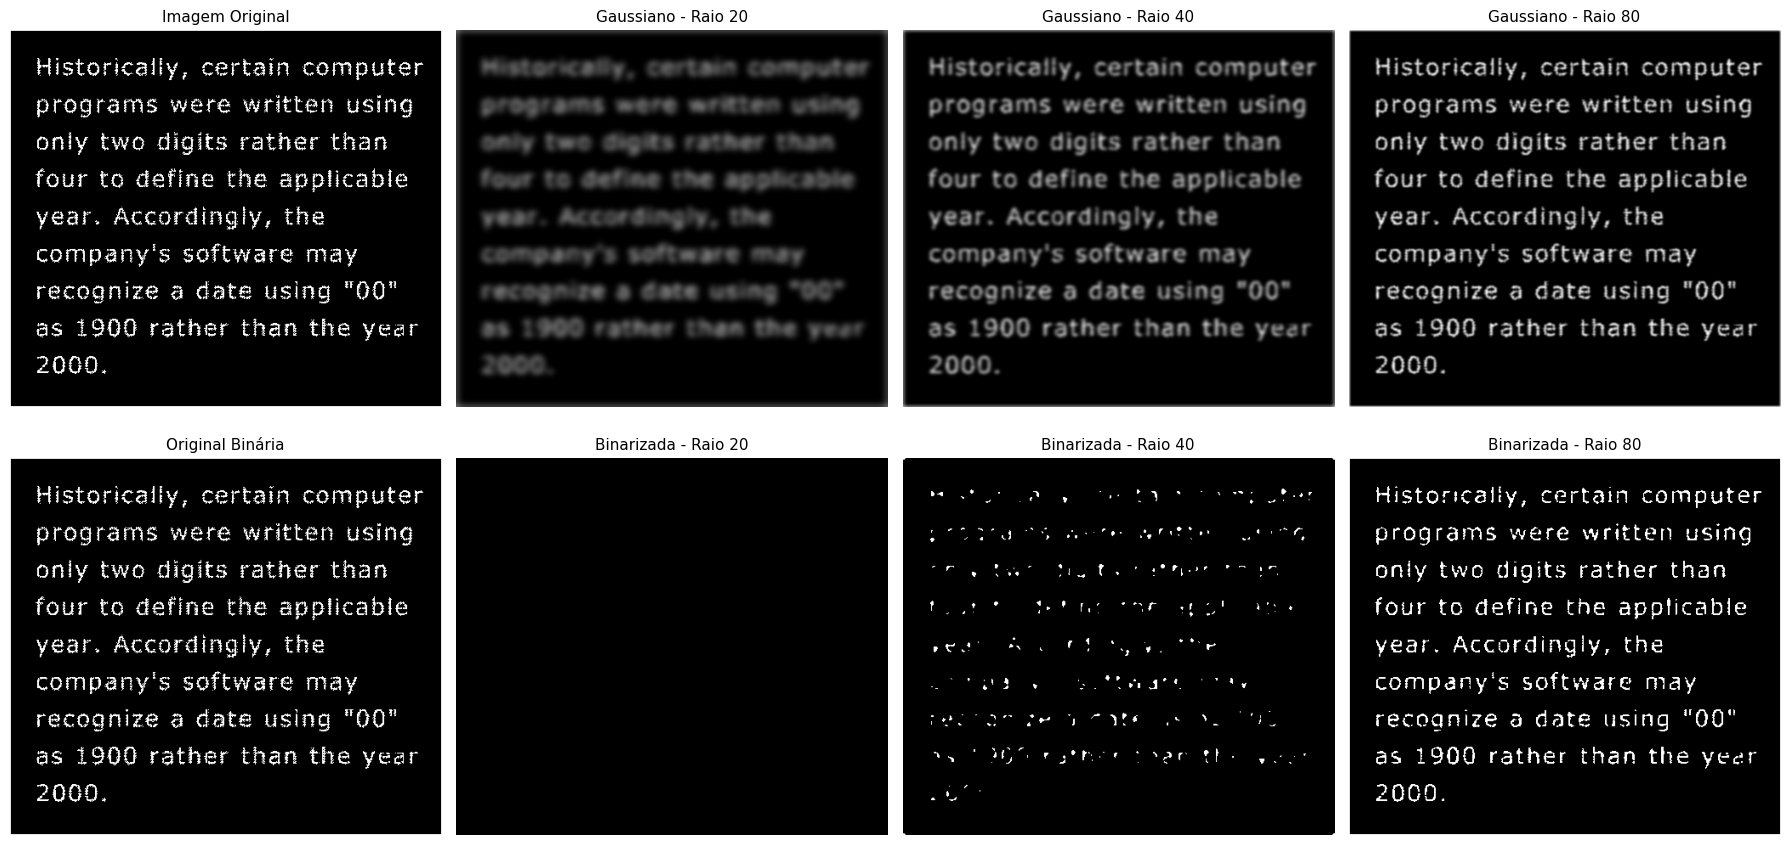

In [ ]:
# CARREGAMENTO DA IMAGEM
img_texto = cv2.imread('/content/Fig0907(a)(text_gaps_1_and_2_pixels).tif', 0)

# FUNÇÃO PARA CRIAR O FILTRO GAUSSIANO PASSA-BAIXA
def criar_filtro_gaussiano(shape, raio):

    if raio <= 0:
        raise ValueError("O raio deve ser maior que zero.")

    rows, cols = shape[:2]

    # Define o centro do espectro de frequências
    crow, ccol = rows // 2, cols // 2

    # Cria a matriz de distâncias até o centro
    y, x = np.ogrid[:rows, :cols]

    distancia = (x - ccol)**2 + (y - crow)**2

    # Fórmula do Filtro Gaussiano Passa-Baixa
    filtro = np.exp(-distancia / (2 * raio**2))

    # Cria a máscara para os canais real e imaginário
    mascara = np.zeros((rows, cols, 2), dtype=np.float32)

    mascara[:, :, 0] = filtro
    mascara[:, :, 1] = filtro

    return mascara


# FUNÇÃO PARA APLICAR O FILTRO NO DOMÍNIO DA FREQUÊNCIA
def aplicar_filtro_gaussiano_frequencia(img, raio):

    # Converte a imagem para float32
    img_float = np.float32(img)

    # Calcula a Transformada Discreta de Fourier
    dft = cv2.dft(
        img_float,
        flags=cv2.DFT_COMPLEX_OUTPUT
    )

    # Desloca as baixas frequências para o centro
    dft_shift = np.fft.fftshift(dft, axes=(0, 1))

    # Cria a máscara Gaussiana
    mascara = criar_filtro_gaussiano(dft_shift.shape, raio)

    # Aplica o filtro no domínio da frequência
    frequencia_filtrada = dft_shift * mascara

    # Desfaz o deslocamento do espectro
    f_ishift = np.fft.ifftshift(
        frequencia_filtrada,
        axes=(0, 1)
    )

    # Aplica a Transformada Inversa de Fourier
    img_back = cv2.idft(
        f_ishift,
        flags=cv2.DFT_SCALE | cv2.DFT_REAL_OUTPUT
    )

    # Limita os valores ao intervalo de 0 a 255
    img_filtrada = np.clip(img_back, 0, 255)

    return img_filtrada.astype(np.uint8)


# FUNÇÃO PARA EXIBIR OS RESULTADOS
def exibir_resultados_gaussiano(original, resultados):

    fig, axes = plt.subplots(2, 4, figsize=(18, 9))

    # Imagem original na primeira coluna
    axes[0, 0].imshow(
        original, cmap='gray', vmin=0, vmax=255
    )
    axes[0, 0].set_title("Imagem Original", fontsize=11)
    axes[0, 0].axis('off')

    # Imagem original binarizada
    axes[1, 0].imshow(
        original, cmap='gray', vmin=0, vmax=255
    )
    axes[1, 0].set_title("Original Binária", fontsize=11)
    axes[1, 0].axis('off')

    # Exibe os três resultados
    for indice, (raio, imagens) in enumerate(resultados.items(), 1):

        # Resultado da filtragem Gaussiana
        axes[0, indice].imshow(
            imagens["filtrada"],
            cmap='gray',
            vmin=0,
            vmax=255
        )

        axes[0, indice].set_title(
            f"Gaussiano - Raio {raio}", fontsize=11
        )
        axes[0, indice].axis('off')

        # Resultado após binarização
        axes[1, indice].imshow(
            imagens["binaria"],
            cmap='gray',
            vmin=0,
            vmax=255
        )

        axes[1, indice].set_title(
            f"Binarizada - Raio {raio}", fontsize=11
        )
        axes[1, indice].axis('off')

    plt.tight_layout()
    plt.show()


# APLICAÇÃO DO FILTRO GAUSSIANO
# Testa três valores diferentes de raio
def executar_experimento_gaussiano(img):

    # Binariza a imagem para trabalhar com o texto
    img_binaria = binarizar_imagem(img, inverter=False)

    # Raios utilizados no experimento
    raios = [20, 40, 80]

    resultados = {}

    for raio in raios:

        print(f"Aplicando Filtro Gaussiano - Raio {raio}...")

        # Filtragem no domínio da frequência
        img_filtrada = aplicar_filtro_gaussiano_frequencia(
            img_binaria, raio
        )

        # Binarização após a filtragem
        _, img_reconstruida = cv2.threshold(
            img_filtrada,
            127,
            255,
            cv2.THRESH_BINARY
        )

        # Armazena os resultados
        resultados[raio] = {
            "filtrada": img_filtrada,
            "binaria": img_reconstruida
        }

    print("Filtragem concluída! Gerando comparação...")

    # Exibe os resultados
    exibir_resultados_gaussiano(img_binaria, resultados)

    return img_binaria, resultados


# EXECUÇÃO
img_texto_binaria, resultados_gaussiano = executar_experimento_gaussiano(
    img_texto
)

# 9. Comparação visual entre as duas técnicas

## Justificativa da aplicação

Para este experimento, serão utilizadas operações de dilatação e fechamento morfológico com o objetivo de reconstruir caracteres que apresentam pequenas falhas e interrupções.

Diferentemente do Filtro Gaussiano na frequência, que busca suavizar as variações de intensidade da imagem, as operações morfológicas atuam diretamente sobre a forma e a organização espacial dos objetos, utilizando elementos estruturantes.

A dilatação permite expandir os pixels brancos, preenchendo pequenas interrupções entre os traços dos caracteres. Entretanto, essa expansão também pode aumentar excessivamente a espessura das letras e provocar a união de regiões próximas.

O fechamento morfológico, formado pela dilatação seguida da erosão, busca preencher pequenas lacunas e recuperar parcialmente a espessura original dos caracteres, preservando melhor suas características estruturais.

Serão testadas três configurações:

- **Dilatação com cruz 3×3:** para preencher pequenas falhas, utilizando um elemento estruturante que provoca uma expansão mais moderada.
- **Fechamento com quadrado 3×3:** para avaliar o preenchimento das interrupções e a preservação da espessura dos caracteres.
- **Fechamento com quadrado 5×5:** para verificar se um elemento estruturante maior consegue recuperar lacunas mais extensas, considerando o risco de unir caracteres próximos.

O objetivo é identificar qual configuração apresenta o melhor equilíbrio entre preenchimento das falhas, preservação dos detalhes e legibilidade do texto, para posteriormente comparar seus resultados com os obtidos pelo Filtro Gaussiano no domínio da frequência.


Aplicando dilatação com cruz 3x3...
Aplicando fechamento com quadrado 3x3...
Aplicando fechamento com quadrado 5x5...
Processamento concluído! Gerando comparação...


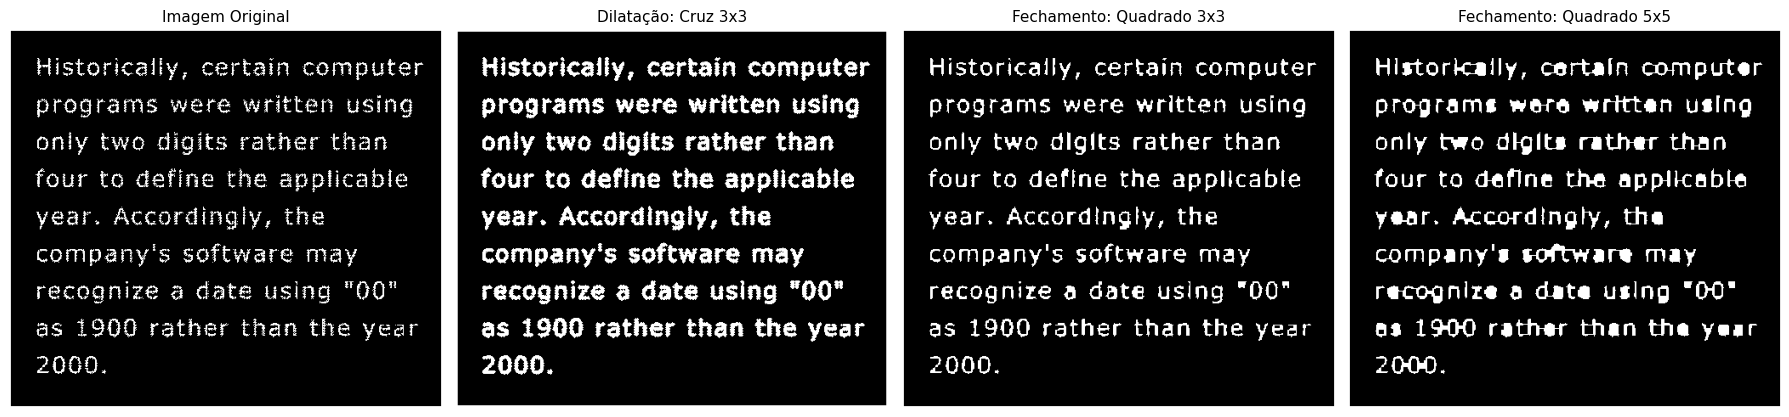

In [ ]:
# FUNÇÃO PARA EXIBIR OS RESULTADOS
# Compara a imagem original com as três configurações
def exibir_resultados_morfologicos_texto(original, resultados):

    fig, axes = plt.subplots(1, 4, figsize=(18, 6))

    # Imagem original
    axes[0].imshow(
        original,
        cmap='gray',
        vmin=0,
        vmax=255
    )
    axes[0].set_title("Imagem Original", fontsize=11)
    axes[0].axis('off')

    # Imagens processadas
    for indice, (nome, imagem) in enumerate(resultados.items(), 1):

        axes[indice].imshow(
            imagem,
            cmap='gray',
            vmin=0,
            vmax=255
        )

        axes[indice].set_title(nome, fontsize=11)
        axes[indice].axis('off')

    plt.tight_layout()
    plt.show()


# APLICAÇÃO DO PROCESSAMENTO MORFOLÓGICO
# Testa dilatação e fechamento com diferentes elementos
def executar_experimento_morfologico_texto(img):

    # Criação dos elementos estruturantes
    kernel_cruz_3x3 = criar_elemento_estruturante(
        3, "cruz"
    )

    kernel_quadrado_3x3 = criar_elemento_estruturante(
        3, "quadrado"
    )

    kernel_quadrado_5x5 = criar_elemento_estruturante(
        5, "quadrado"
    )

    # ETAPA 1: DILATAÇÃO CRUZ 3x3
    print("Aplicando dilatação com cruz 3x3...")

    img_dilatacao_cruz = aplicar_dilatacao(
        img, kernel_cruz_3x3
    )

    # ETAPA 2: FECHAMENTO QUADRADO 3x3
    print("Aplicando fechamento com quadrado 3x3...")

    img_fechamento_3x3 = aplicar_fechamento(
        img, kernel_quadrado_3x3
    )

    # ETAPA 3: FECHAMENTO QUADRADO 5x5
    print("Aplicando fechamento com quadrado 5x5...")

    img_fechamento_5x5 = aplicar_fechamento(
        img, kernel_quadrado_5x5
    )

    print("Processamento concluído! Gerando comparação...")

    # Organiza os resultados
    resultados = {
        "Dilatação: Cruz 3x3": img_dilatacao_cruz,
        "Fechamento: Quadrado 3x3": img_fechamento_3x3,
        "Fechamento: Quadrado 5x5": img_fechamento_5x5
    }

    # Exibe as imagens
    exibir_resultados_morfologicos_texto(img, resultados)

    return resultados


# EXECUÇÃO
# Reutiliza a mesma imagem utilizada no Filtro Gaussiano
resultados_morfologicos_texto = executar_experimento_morfologico_texto(
    img_texto_binaria
)

# 10. Análise conjunta dos resultados

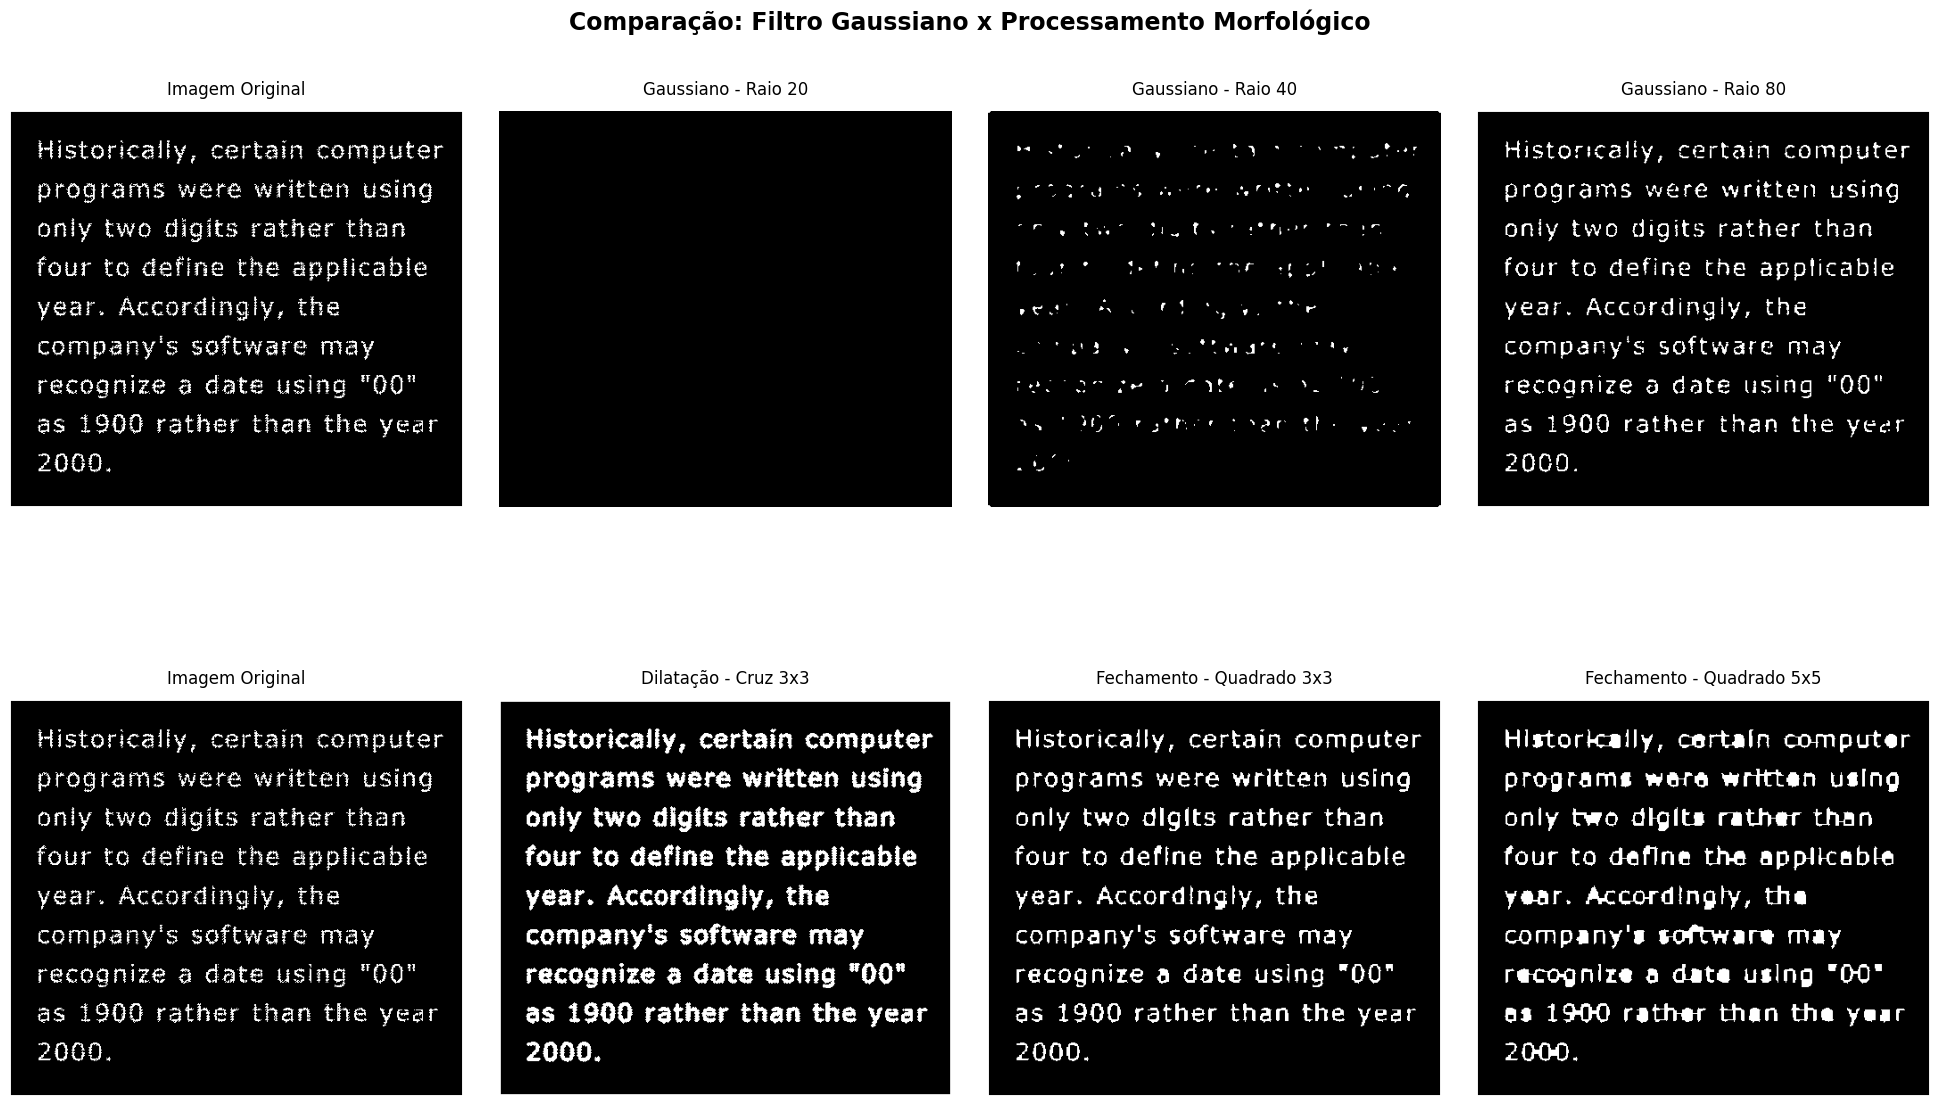

In [ ]:

# FUNÇÃO PARA COMPARAR OS RESULTADOS
# Exibe os resultados do Filtro Gaussiano e do Processamento Morfológico lado a lado

def exibir_comparacao_final(original, gaussianos, morfologicos):

    fig, axes = plt.subplots(2, 4, figsize=(20, 10))

    fig.suptitle(
        "Comparação: Filtro Gaussiano x Processamento Morfológico",
        fontsize=16,
        fontweight='bold'
    )

    # PRIMEIRA LINHA: FILTRO GAUSSIANO
    imagens_gaussiano = [
        original,
        gaussianos[20]["binaria"],
        gaussianos[40]["binaria"],
        gaussianos[80]["binaria"]
    ]

    titulos_gaussiano = [
        "Imagem Original",
        "Gaussiano - Raio 20",
        "Gaussiano - Raio 40",
        "Gaussiano - Raio 80"
    ]

    for i in range(4):
        axes[0, i].imshow(
            imagens_gaussiano[i],
            cmap='gray',
            vmin=0,
            vmax=255
        )
        axes[0, i].set_title(titulos_gaussiano[i], fontsize=12)
        axes[0, i].axis('off')

    # SEGUNDA LINHA: PROCESSAMENTO MORFOLÓGICO
    imagens_morfologia = [
        original,
        morfologicos["Dilatação: Cruz 3x3"],
        morfologicos["Fechamento: Quadrado 3x3"],
        morfologicos["Fechamento: Quadrado 5x5"]
    ]

    titulos_morfologia = [
        "Imagem Original",
        "Dilatação - Cruz 3x3",
        "Fechamento - Quadrado 3x3",
        "Fechamento - Quadrado 5x5"
    ]

    for i in range(4):
        axes[1, i].imshow(
            imagens_morfologia[i],
            cmap='gray',
            vmin=0,
            vmax=255
        )
        axes[1, i].set_title(titulos_morfologia[i], fontsize=12)
        axes[1, i].axis('off')

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()



# FUNÇÃO PARA COMPARAR OS RESULTADOS
# Exibe os resultados com maior espaçamento entre as linhas

def exibir_comparacao_final(original, gaussianos, morfologicos):

    # Aumenta a altura da figura
    fig, axes = plt.subplots(2, 4, figsize=(20, 12))

    fig.suptitle(
        "Comparação: Filtro Gaussiano x Processamento Morfológico",
        fontsize=17,
        fontweight='bold',
        y=0.97
    )

    # PRIMEIRA LINHA: FILTRO GAUSSIANO
    imagens_gaussiano = [
        original,
        gaussianos[20]["binaria"],
        gaussianos[40]["binaria"],
        gaussianos[80]["binaria"]
    ]

    titulos_gaussiano = [
        "Imagem Original",
        "Gaussiano - Raio 20",
        "Gaussiano - Raio 40",
        "Gaussiano - Raio 80"
    ]

    for i in range(4):
        axes[0, i].imshow(
            imagens_gaussiano[i],
            cmap='gray',
            vmin=0,
            vmax=255
        )
        axes[0, i].set_title(
            titulos_gaussiano[i], fontsize=12, pad=12
        )
        axes[0, i].axis('off')

    # SEGUNDA LINHA: PROCESSAMENTO MORFOLÓGICO
    imagens_morfologia = [
        original,
        morfologicos["Dilatação: Cruz 3x3"],
        morfologicos["Fechamento: Quadrado 3x3"],
        morfologicos["Fechamento: Quadrado 5x5"]
    ]

    titulos_morfologia = [
        "Imagem Original",
        "Dilatação - Cruz 3x3",
        "Fechamento - Quadrado 3x3",
        "Fechamento - Quadrado 5x5"
    ]

    for i in range(4):
        axes[1, i].imshow(
            imagens_morfologia[i],
            cmap='gray',
            vmin=0,
            vmax=255
        )
        axes[1, i].set_title(
            titulos_morfologia[i], fontsize=12, pad=12
        )
        axes[1, i].axis('off')

    plt.subplots_adjust(
        left=0.02,
        right=0.98,
        top=0.89,
        bottom=0.06,
        hspace=0.45,
        wspace=0.08
    )

    plt.show()


# EXECUÇÃO DA COMPARAÇÃO
exibir_comparacao_final(
    img_texto_binaria,
    resultados_gaussiano,
    resultados_morfologicos_texto
)



## Filtragem Gaussiana na Frequência

A aplicação do Filtro Gaussiano demonstrou como a intensidade da suavização influencia a preservação dos caracteres e a reconstrução das falhas do texto.

**Raio 20:** Provocou um desfoque intenso, fazendo com que praticamente todo o texto desaparecesse após a binarização, resultando em perda de informação.

**Raio 40:** Apresentou uma suavização menos intensa, porém a binarização preservou apenas pequenos fragmentos das letras, tornando o texto ilegível.

**Raio 80:** Apresentou o melhor resultado entre os filtros Gaussianos, mantendo a legibilidade e preservando grande parte dos caracteres. Entretanto, muitas das falhas originais permaneceram.

De maneira geral, a filtragem Gaussiana apresentou limitações na reconstrução do texto. Os raios menores causaram perda significativa de informação após a binarização, enquanto o raio maior preservou melhor os detalhes, mas não preencheu satisfatoriamente as descontinuidades.

### Processamento Morfológico

**Dilatação com cruz 3×3:** Aumentou a espessura das letras e preencheu pequenas falhas, melhorando a continuidade dos caracteres. Entretanto, também provocou a aproximação de alguns traços, alterando parcialmente suas formas.

**Fechamento com quadrado 3×3:** Apresentou o melhor equilíbrio entre preenchimento das falhas e preservação das letras. A dilatação conectou pequenas interrupções, enquanto a erosão reduziu a expansão excessiva, mantendo boa legibilidade.

**Fechamento com quadrado 5×5:** Produziu um preenchimento mais intenso, mas provocou a união indesejada de traços próximos, deformando algumas letras e dificultando sua leitura.

Os resultados demonstraram que o processamento morfológico conseguiu recuperar parte das descontinuidades, embora elementos estruturantes maiores tenham causado perda de definição.

### Comparação entre as Técnicas

As técnicas apresentaram comportamentos diferentes. O Filtro Gaussiano suavizou as intensidades da imagem, mas não conseguiu reconstruir satisfatoriamente as falhas sem comprometer a legibilidade. Já o processamento morfológico atuou diretamente sobre a forma dos caracteres, permitindo preencher pequenas interrupções.

Entre as configurações avaliadas, o fechamento morfológico com quadrado 3×3 apresentou o resultado visual mais equilibrado, preservando melhor o formato das letras e reduzindo parte das falhas. O Filtro Gaussiano com raio 80 apresentou o melhor resultado entre os filtros de frequência, mas manteve muitas descontinuidades.

### Conclusão

A comparação demonstrou que, nas configurações testadas, o processamento morfológico foi mais eficiente na reconstrução visual do texto. O fechamento com quadrado 3×3 apresentou o melhor equilíbrio entre recuperação das falhas e preservação da legibilidade.

Entretanto, os resultados dependem dos parâmetros utilizados e das características da imagem. Portanto, a escolha da técnica deve considerar o tipo de degradação e o objetivo do processamento.

